# Portfolio edition

Academic project completed during the TripleTen Data Science program. The assignment context and datasets were supplied by the program. Analysis and code are in Spanish; the README provides an English overview.

**Execution provenance:** outputs and reported metrics come from the original October 2026 execution. This portfolio copy has not been retrained. Local data paths, metadata and a few API compatibility calls were adapted in November 2026; those edits are documented in `REVIEW.md`. Re-execution with a different environment may produce different results. Read the README limitations before interpreting these results as future predictive performance.

Datasets and trained model weights are not distributed. See `DATA.md` for the expected layout.


## Inicialización

## Cargar datos

El conjunto de datos se almacena en la carpeta `data/faces/`
- La carpeta `final_files` con 7600 fotos
- El archivo `labels.csv` con leyendas, con dos columnas: `file_name` y `real_age`

Dado que el número de archivos de imágenes es bastante elevado, se recomienda evitar leerlos todos a la vez, ya que esto consumiría muchos recursos computacionales. Te recomendamos crear un generador con ImageDataGenerator. Este método se explicó en el capítulo 3, lección 7 de este curso.

El archivo de etiqueta se puede cargar como un archivo CSV habitual.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tensorflow.keras.preprocessing.image import ImageDataGenerator

labels = pd.read_csv('data/faces/labels.csv')

labels.info()
display(labels.head())
print('Duplicados en file_name:', labels['file_name'].duplicated().sum())

# generador: las imágenes se leen por lotes desde la carpeta, no todas a la vez
datagen = ImageDataGenerator(rescale=1./255)
datagen_flow = datagen.flow_from_dataframe(
    dataframe=labels,
    directory='data/faces/final_files/',
    x_col='file_name',
    y_col='real_age',
    target_size=(224, 224),
    batch_size=32,
    class_mode='raw',
    seed=12345,
)

## EDA

Tamaño del conjunto: 7591 fotos


count    7591.000000
mean       31.201159
std        17.145060
min         1.000000
25%        20.000000
50%        29.000000
75%        41.000000
max       100.000000
Name: real_age, dtype: float64

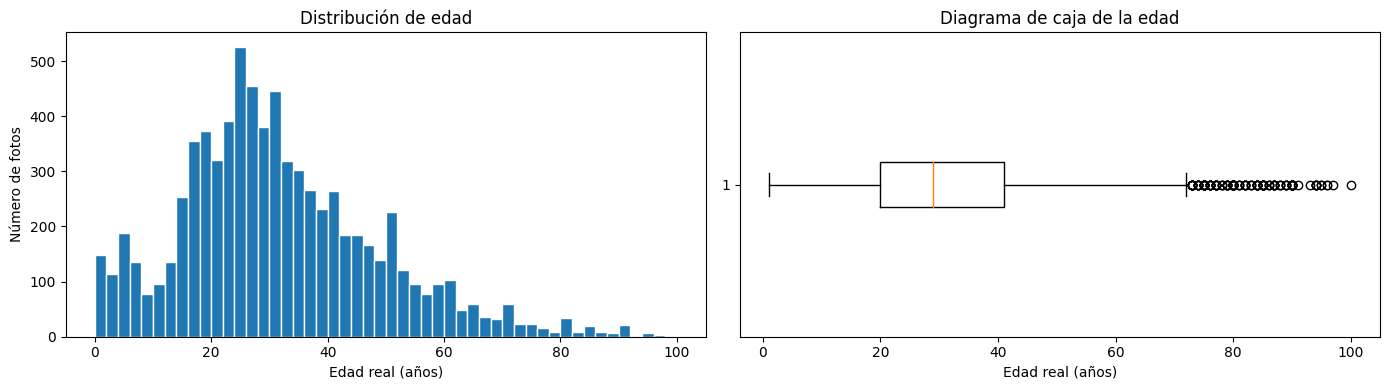

,fotos,%
1-12,815,10.7
13-17,688,9.1
18-24,1297,17.1
25-34,2071,27.3
35-49,1584,20.9
50-64,789,10.4
65+,347,4.6


Menores de 18: 1503 fotos (19.8%)
Fotos en edades redondas frente a sus edades vecinas:


,edad,fotos,promedio_vecinos_±2
0,30,317,171.0
1,40,167,107.0
2,50,156,71.5
3,60,75,37.8
4,70,50,14.0
5,80,31,4.2


In [5]:
print('Tamaño del conjunto:', labels.shape[0], 'fotos')
display(labels['real_age'].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(labels['real_age'], bins=range(0, 102, 2), edgecolor='white')
axes[0].set_xlabel('Edad real (años)')
axes[0].set_ylabel('Número de fotos')
axes[0].set_title('Distribución de edad')
axes[1].boxplot(labels['real_age'], vert=False)
axes[1].set_xlabel('Edad real (años)')
axes[1].set_title('Diagrama de caja de la edad')
plt.tight_layout()
plt.show()

# fotos por grupo de edad, con atención especial al umbral legal de 18 años
bins = [0, 13, 18, 25, 35, 50, 65, 101]
groups = ['1-12', '13-17', '18-24', '25-34', '35-49', '50-64', '65+']
age_groups = pd.cut(labels['real_age'], bins=bins, labels=groups, right=False)
summary = age_groups.value_counts().sort_index().to_frame('fotos')
summary['%'] = (summary['fotos'] / len(labels) * 100).round(1)
display(summary)
print('Menores de 18:', (labels['real_age'] < 18).sum(), 'fotos',
      f"({(labels['real_age'] < 18).mean():.1%})")

# ¿hay más fotos en edades redondas (posible etiquetado aproximado)?
counts = labels['real_age'].value_counts()
round_vs_neighbors = pd.DataFrame({
    'edad': [30, 40, 50, 60, 70, 80],
    'fotos': [counts.get(a, 0) for a in [30, 40, 50, 60, 70, 80]],
    'promedio_vecinos_±2': [round(np.mean([counts.get(a + d, 0) for d in (-2, -1, 1, 2)]), 1)
                            for a in [30, 40, 50, 60, 70, 80]],
})
print('Fotos en edades redondas frente a sus edades vecinas:')
display(round_vs_neighbors)

In [4]:
# tamaños originales de una muestra de fotos
sample = labels.sample(200, random_state=12345)
sizes = pd.DataFrame([Image.open('data/faces/final_files/' + f).size for f in sample['file_name']],
                     columns=['ancho', 'alto'])
print('Tamaño original (px) en una muestra de 200 fotos:')
display(sizes.describe().round(0))
print('Fotos cuadradas:', f"{(sizes['ancho'] == sizes['alto']).mean():.0%}")

# 15 fotos de edades distintas, ordenadas de menor a mayor
rng = np.random.RandomState(12345)
show_ages = [1, 4, 8, 12, 15, 17, 18, 21, 25, 30, 40, 50, 60, 75, 90]
fig = plt.figure(figsize=(15, 9))
for i, age in enumerate(show_ages):
    candidates = labels[labels['real_age'] == age]
    if candidates.empty:
        candidates = labels.iloc[(labels['real_age'] - age).abs().argsort()[:5]]
    row = candidates.iloc[rng.randint(len(candidates))]
    img = Image.open('data/faces/final_files/' + row['file_name'])
    fig.add_subplot(3, 5, i + 1)
    plt.imshow(img)
    plt.title(f"{row['real_age']} años")
    plt.xticks([])
    plt.yticks([])
plt.tight_layout()
plt.show()

### Conclusiones

**Hallazgos del EDA y cómo afectan al entrenamiento**

- **Tamaño:** hay 7591 fotos con su edad real, sin valores ausentes ni nombres de archivo duplicados. Para entrenar una red desde cero es un conjunto pequeño, así que conviene usar **transfer learning** (ResNet50 preentrenada en ImageNet) en lugar de entrenar desde cero.
- **Distribución de edad:** va de 1 a 100 años, con media de 31.2 y mediana de 29. Tiene sesgo a la derecha: el 65 % de las fotos está entre 18 y 49 años y solo el 4.6 % tiene 65 años o más. El modelo verá pocas personas mayores, así que es de esperar un error mayor en esas edades.
- **Umbral legal:** 1503 fotos (19.8 %) son de menores de 18 años (815 de 1-12 y 688 de 13-17). Es una base razonable para la tarea, pero el rango que más importa (15-25 años) es justo donde un error de 2-3 años cambia la decisión, así que además del EAM global conviene revisar el error alrededor de los 18.
- **Etiquetas aproximadas:** hay picos en edades redondas (por ejemplo, 317 fotos de 30 años frente a unas 171 en sus edades vecinas, y 156 de 50 frente a 72). Parte de las edades parece estimada o redondeada, lo que pone un piso al error que puede alcanzar el modelo.
- **Imágenes:** los rostros ya vienen recortados y alineados, pero varían mucho en tamaño (de 57 a más de 2000 px de lado; 74 % cuadradas), en iluminación y en calidad (algunas pixeladas o borrosas). Varias están rotadas, con bordes negros de relleno. Por eso todas se redimensionan a 224x224, se normalizan a [0, 1], y para entrenar se usa un aumento suave (reflejo horizontal). Rotaciones fuertes o reflejos verticales no aportan, porque las caras ya están alineadas.
- **Función de pérdida y métrica:** es una tarea de regresión con una sola neurona de salida y activación ReLU (la edad no puede ser negativa). Se optimiza el ECM y se mide el **EAM**, que se interpreta directamente en años; la meta es EAM ≤ 8.

## Modelado

Define las funciones necesarias para entrenar tu modelo en la plataforma GPU y crear un solo script que las contenga todas junto con la sección de inicialización.

Para facilitar esta tarea, puedes definirlas en este notebook y ejecutar un código listo en la siguiente sección para componer automáticamente el script.

Los revisores del proyecto también verificarán las definiciones a continuación, para que puedan comprender cómo construiste el modelo.

In [6]:
import pandas as pd

import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Flatten
from tensorflow.keras.optimizers import Adam

In [7]:
def load_train(path):
    
    """
    Carga la parte de entrenamiento del conjunto de datos desde la ruta.
    75 % de las fotos; aumento: solo reflejo horizontal (una cara reflejada tiene la misma edad).
    """
    
    labels = pd.read_csv(path + 'labels.csv')
    train_datagen = ImageDataGenerator(
        rescale=1./255,
        validation_split=0.25,
        horizontal_flip=True,
    )
    train_gen_flow = train_datagen.flow_from_dataframe(
        dataframe=labels,
        directory=path + 'final_files/',
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',
        subset='training',
        seed=12345,
    )

    return train_gen_flow

In [8]:
def load_test(path):
    
    """
    Carga la parte de validación/prueba del conjunto de datos desde la ruta.
    25 % de las fotos, sin aumentos.
    """
    
    labels = pd.read_csv(path + 'labels.csv')
    test_datagen = ImageDataGenerator(
        rescale=1./255,
        validation_split=0.25,
    )
    test_gen_flow = test_datagen.flow_from_dataframe(
        dataframe=labels,
        directory=path + 'final_files/',
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',
        subset='validation',
        seed=12345,
    )

    return test_gen_flow

In [9]:
def create_model(input_shape):
    
    """
    Define el modelo: ResNet50 preentrenada en ImageNet + una neurona de salida con ReLU
    (la edad no puede ser negativa). Pérdida ECM, métrica EAM.
    """
    
    backbone = ResNet50(
        input_shape=input_shape,
        weights='imagenet',
        include_top=False,
    )
    model = Sequential()
    model.add(backbone)
    model.add(GlobalAveragePooling2D())
    model.add(Dense(1, activation='relu'))

    optimizer = Adam(learning_rate=0.0001)
    model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

    return model

In [10]:
def train_model(model, train_data, test_data, batch_size=None, epochs=20,
                steps_per_epoch=None, validation_steps=None):

    """
    Entrena el modelo dados los parámetros
    """
    
    if steps_per_epoch is None:
        steps_per_epoch = len(train_data)
    if validation_steps is None:
        validation_steps = len(test_data)

    model.fit(
        train_data,
        validation_data=test_data,
        batch_size=batch_size,
        epochs=epochs,
        steps_per_epoch=steps_per_epoch,
        validation_steps=validation_steps,
        verbose=2,
    )

    return model

### Prepara el script para ejecutarlo en la plataforma GPU

Una vez que hayas definido las funciones necesarias, puedes redactar un script para la plataforma GPU, descargarlo a través del menú "File|Open..." (Archivo|Abrir) y cargarlo más tarde para ejecutarlo en la plataforma GPU.

Nota: el script debe incluir también la sección de inicialización. A continuación se muestra un ejemplo.

In [11]:
# prepara un script para ejecutarlo en la plataforma GPU

init_str = """
import pandas as pd

import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Flatten
from tensorflow.keras.optimizers import Adam
"""

import inspect

with open('run_model_on_gpu.py', 'w') as f:
    
    f.write(init_str)
    f.write('\n\n')
        
    for fn_name in [load_train, load_test, create_model, train_model]:
        
        src = inspect.getsource(fn_name)
        f.write(src)
        f.write('\n\n')

### Resultado

Coloca aquí el resultado de la plataforma GPU como una celda Markdown.

El script se ejecutó en una GPU NVIDIA RTX 3060 Ti (8 GB) con TensorFlow 2.15.1; cada época tardó ~29 s (≈10 min en total).

```
Found 5694 validated image filenames.
Found 1897 validated image filenames.
Epoch 1/20
178/178 - 60s - loss: 269.9504 - mae: 11.7506 - val_loss: 701.8716 - val_mae: 21.5565 - 60s/epoch - 335ms/step
Epoch 2/20
178/178 - 28s - loss: 84.8972 - mae: 6.9198 - val_loss: 643.2880 - val_mae: 20.3224 - 28s/epoch - 156ms/step
Epoch 3/20
178/178 - 28s - loss: 53.9671 - mae: 5.5957 - val_loss: 312.4690 - val_mae: 13.1302 - 28s/epoch - 158ms/step
Epoch 4/20
178/178 - 28s - loss: 40.7877 - mae: 4.8258 - val_loss: 160.7753 - val_mae: 9.5430 - 28s/epoch - 159ms/step
Epoch 5/20
178/178 - 28s - loss: 34.1798 - mae: 4.4546 - val_loss: 100.1446 - val_mae: 7.5456 - 28s/epoch - 159ms/step
Epoch 6/20
178/178 - 29s - loss: 27.5473 - mae: 3.9823 - val_loss: 80.4343 - val_mae: 6.9412 - 29s/epoch - 163ms/step
Epoch 7/20
178/178 - 29s - loss: 23.4706 - mae: 3.7187 - val_loss: 63.4572 - val_mae: 5.9649 - 29s/epoch - 161ms/step
Epoch 8/20
178/178 - 29s - loss: 19.2781 - mae: 3.3177 - val_loss: 66.3962 - val_mae: 6.1074 - 29s/epoch - 161ms/step
Epoch 9/20
178/178 - 29s - loss: 18.5403 - mae: 3.2758 - val_loss: 96.8220 - val_mae: 7.7976 - 29s/epoch - 162ms/step
Epoch 10/20
178/178 - 29s - loss: 15.7287 - mae: 3.0474 - val_loss: 82.5380 - val_mae: 6.7135 - 29s/epoch - 162ms/step
Epoch 11/20
178/178 - 29s - loss: 13.6759 - mae: 2.8307 - val_loss: 65.6197 - val_mae: 6.1394 - 29s/epoch - 163ms/step
Epoch 12/20
178/178 - 29s - loss: 13.0583 - mae: 2.7742 - val_loss: 98.1037 - val_mae: 7.2104 - 29s/epoch - 164ms/step
Epoch 13/20
178/178 - 29s - loss: 12.7541 - mae: 2.7292 - val_loss: 84.0370 - val_mae: 7.0765 - 29s/epoch - 164ms/step
Epoch 14/20
178/178 - 29s - loss: 12.8180 - mae: 2.7581 - val_loss: 67.7945 - val_mae: 6.0834 - 29s/epoch - 165ms/step
Epoch 15/20
178/178 - 29s - loss: 12.5829 - mae: 2.7125 - val_loss: 60.2566 - val_mae: 5.7592 - 29s/epoch - 165ms/step
Epoch 16/20
178/178 - 30s - loss: 10.7112 - mae: 2.5081 - val_loss: 66.4085 - val_mae: 6.0301 - 30s/epoch - 167ms/step
Epoch 17/20
178/178 - 30s - loss: 9.5412 - mae: 2.3582 - val_loss: 63.7618 - val_mae: 5.8685 - 30s/epoch - 167ms/step
Epoch 18/20
178/178 - 30s - loss: 9.6405 - mae: 2.3895 - val_loss: 63.9678 - val_mae: 6.0252 - 30s/epoch - 167ms/step
Epoch 19/20
178/178 - 30s - loss: 8.2671 - mae: 2.2136 - val_loss: 58.4486 - val_mae: 5.7715 - 30s/epoch - 166ms/step
Epoch 20/20
178/178 - 30s - loss: 8.6834 - mae: 2.2464 - val_loss: 60.7939 - val_mae: 5.9011 - 30s/epoch - 167ms/step
```

## Conclusiones

**Portfolio interpretation of the historical training run**

The final validation MAE was **5.90 years**; the best observed validation epoch was **5.76 years** (epoch 15). The training MAE fell to 2.25 years, indicating a substantial train/validation gap. More epochs are not demonstrated to improve generalization.

This is a random image split, not a verified identity-disjoint or external test set. Identity overlap, age imbalance and label uncertainty can affect the result. The aggregate MAE does not establish performance near age 18 or for underrepresented age groups.

Potential improvements include identity-disjoint validation, age-group error analysis, early stopping/checkpointing and comparison of the current rescaling with the preprocessing expected by the pretrained ResNet50 weights. Those experiments have not been performed here.

No real-time system, retail deployment, age verification accuracy or commercial impact was measured. The model should not be presented as an age-verification system.


# Lista de revisión

- [x]  El Notebook estaba abierto 
- [x]  El código no tiene errores
- [x]  Las celdas con el código han sido colocadas en el orden de ejecución
- [x]  Se realizó el análisis exploratorio de datos
- [x]  Los resultados del análisis exploratorio de datos se presentan en el notebook final
- [x]  El valor EAM del modelo no es superior a 8
- [x]  El código de entrenamiento del modelo se copió en el notebook final
- [x]  El resultado de entrenamiento del modelo se copió en el notebook final
- [x]  Los hallazgos se proporcionaron con base en los resultados del entrenamiento del modelo